# ⚡ Electric Vehicle (EV) Market Analysis: Adoption Trends, Consumer  Preferences & Future Demand Forecasting

*An end-to-end analytics project: from raw Department of Licensing records to clean, labelled visuals and data-driven findings.*

---

## 🎯 Project Goal
To understand **what the electric vehicle fleet in Washington State looks like**: which vehicle types, makes and models dominate, how the fleet has grown across model years, how electric range has changed, and where the vehicles are concentrated. The aim is to turn raw registration records into clear evidence that can support clean-mobility and charging-infrastructure planning.

## ✅ Objectives
1. **Prepare reliable data:** standardize column names and text, remove duplicates, handle missing and impossible values, and treat outliers in electric range.
2. **Describe the fleet:** measure the split between Battery Electric Vehicles (BEV) and Plug-in Hybrid Electric Vehicles (PHEV), CAFV eligibility, and the leading makes and models.
3. **Track change over time:** show how EV records and median electric range vary by model year, and whether BEVs and PHEVs differ.
4. **Map where EVs are:** compare counties, cities, legislative districts and utilities, and show how concentrated the fleet is.
5. **Compare groups:** contrast manufacturers by BEV/PHEV mix and median range, and compare CAFV eligibility between BEVs and PHEVs.
6. **Communicate honestly:** label every chart with counts, state the limits of the data (for example, many records have no recorded range), and summarize the results in written findings

## 🗂️ Data Profile
| Item | Detail |
|---|---|
| **Source** | Washington State Department of Licensing, via Data.gov |
| **Content** | Battery Electric (BEV) and Plug-in Hybrid (PHEV) vehicle records |
| **Size** | About 300,000 records (299,694 after cleaning) and 17 columns |
| **Key fields** | Make, model, model year, vehicle type, electric range, CAFV eligibility, county, city, location, utility |
| **Unit of analysis** | One record per vehicle in the dataset. This is the observed vehicle population, not necessarily every registration made in each year |
| **Known limitation** | Electric range is recorded for only about one third of records, so range charts describe those vehicles only |

##
1. **Data Loading:**
2. **Data Cleaning:** names, duplicates, missing values, inconsistencies, outliers
3. **Exploratory Data Analysis and Visualizations:**
4. **Summary of Findings:**


## 🛠️ Tools
Python, `pandas`, `numpy`, `matplotlib`, `seaborn`

# 1. DATA LOADING

### Step 1: Upload the data file
Opens the Colab file picker so you can upload `Electric_Vehicle_Population_Data.csv`.

In [1]:
from google.colab import files
uploaded = files.upload()

Saving Electric_Vehicle_Population_Data.csv to Electric_Vehicle_Population_Data.csv


### Step 2: Import libraries and load the data
Imports pandas, numpy, matplotlib and seaborn, sets the chart style, reads the CSV into the DataFrame `df`, and shows the first 10 rows.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Updated to use the correct uploaded filename
df = pd.read_csv("/content/Electric_Vehicle_Population_Data.csv")
df.head(10)

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 GEOID
0,1N4AZ1CP3K,King,Shoreline,WA,98155.0,2019,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,150.0,32.0,168526641,POINT (-122.30304 47.75494),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303302e+10
1,WBY8P4C51K,King,Kirkland,WA,98033.0,2019,BMW,I3,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,126.0,48.0,9418181,POINT (-122.2066 47.67887),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
2,3FA6P0SU8G,Snohomish,Lynnwood,WA,98036.0,2016,FORD,FUSION,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,19.0,1.0,172853495,POINT (-122.29245 47.82557),PUGET SOUND ENERGY INC,5.306105e+10
3,5YJ3E1EB3N,Yakima,Wapato,WA,98951.0,2022,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,15.0,204768175,POINT (-120.42083 46.44779),PACIFICORP,5.307794e+10
4,WBY1Z2C53F,King,Renton,WA,98055.0,2015,BMW,I3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,81.0,11.0,269262920,POINT (-122.19488 47.44034),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10
5,1G1FZ6S00L,Island,Greenbank,WA,98253.0,2020,CHEVROLET,BOLT EV,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,259.0,10.0,268491597,POINT (-122.56817 48.08827),PUGET SOUND ENERGY INC,5.302997e+10
6,KM8HC3A66R,Snohomish,Monroe,WA,98272.0,2024,HYUNDAI,KONA,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,39.0,270749790,POINT (-121.98087 47.8526),PUGET SOUND ENERGY INC,5.306105e+10
7,KM8K53AG7L,Thurston,Olympia,WA,98512.0,2020,HYUNDAI,KONA,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,258.0,35.0,138948988,POINT (-123.04078 46.94792),PUGET SOUND ENERGY INC,5.306701e+10
8,JN1AZ0CP7B,Yakima,Yakima,WA,98901.0,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,14.0,173404556,POINT (-120.50729 46.60464),PACIFICORP,5.307700e+10
9,5YJ3E1EB6L,Kitsap,Silverdale,WA,98383.0,2020,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,322.0,23.0,6335647,POINT (-122.69275 47.65171),PUGET SOUND ENERGY INC,5.303509e+10


# 2. DATA CLEANING

### Step 1: Standardize column names
Converts every column name to lowercase and renames a few long names (for example `vin_prefix` and `cafv_eligibility`) so they are easier to use in code.

In [4]:
import re

def to_snake(name):
    name = re.sub(r"[^0-9a-zA-Z]+", "_", name).strip("_").lower()
    return name

df.columns = [to_snake(c) for c in df.columns]
df = df.rename(columns={
    "vin_1_10": "vin_prefix",
    "clean_alternative_fuel_vehicle_cafv_eligibility": "cafv_eligibility",
    "2020_census_tract": "census_tract_2020",
})

### Step 2: Clean text values
Trims extra spaces in all text columns and turns blank strings into real missing values.

In [5]:
#Trim whitespace and turn blanks into real missing values
text_cols = df.select_dtypes(include=["object", "string"]).columns
for c in text_cols:
    df[c] = df[c].astype("string").str.strip().replace("", pd.NA)

### Step 3: Remove duplicates
Counts exact duplicate rows and duplicate vehicle IDs, then drops them so each vehicle appears once.

In [6]:
#Remove duplicates
print("exact duplicate rows:", df.duplicated().sum())
print("duplicate vehicle IDs:", df["dol_vehicle_id"].duplicated().sum())

df = df.drop_duplicates()
df = df.drop_duplicates(subset="dol_vehicle_id", keep="first")

exact duplicate rows: 0
duplicate vehicle IDs: 0


### Step 4: Handle missing values
Shows how many values are missing per column. A range or price of 0 is treated as "not recorded" and set to missing, and rows without a county, city or postal code are dropped.

In [7]:
#Missing values
df.isna().sum().sort_values(ascending=False)
(df.isna().mean() * 100).round(2)

df["electric_range"] = df["electric_range"].replace(0, np.nan)   # 0 means "not recorded"
if "base_msrp" in df.columns:
    df["base_msrp"] = df["base_msrp"].replace(0, np.nan)

df = df.dropna(subset=["county", "city", "postal_code"])
print(df.head())

   vin_prefix     county       city state  postal_code  model_year    make  \
0  1N4AZ1CP3K       King  Shoreline    WA      98155.0        2019  NISSAN   
1  WBY8P4C51K       King   Kirkland    WA      98033.0        2019     BMW   
2  3FA6P0SU8G  Snohomish   Lynnwood    WA      98036.0        2016    FORD   
3  5YJ3E1EB3N     Yakima     Wapato    WA      98951.0        2022   TESLA   
4  WBY1Z2C53F       King     Renton    WA      98055.0        2015     BMW   

     model                   electric_vehicle_type  \
0     LEAF          Battery Electric Vehicle (BEV)   
1       I3  Plug-in Hybrid Electric Vehicle (PHEV)   
2   FUSION  Plug-in Hybrid Electric Vehicle (PHEV)   
3  MODEL 3          Battery Electric Vehicle (BEV)   
4       I3          Battery Electric Vehicle (BEV)   

                                    cafv_eligibility  electric_range  \
0            Clean Alternative Fuel Vehicle Eligible           150.0   
1            Clean Alternative Fuel Vehicle Eligible          

### Step 5: Preview the cleaned data
Prints the DataFrame to check the result of the cleaning so far.

In [ ]:
print (df)


        vin_prefix     county          city state  postal_code  model_year  \
0       1N4AZ1CP3K       King     Shoreline    WA      98155.0        2019   
1       WBY8P4C51K       King      Kirkland    WA      98033.0        2019   
2       3FA6P0SU8G  Snohomish      Lynnwood    WA      98036.0        2016   
3       5YJ3E1EB3N     Yakima        Wapato    WA      98951.0        2022   
4       WBY1Z2C53F       King        Renton    WA      98055.0        2015   
...            ...        ...           ...   ...          ...         ...   
299700  ZACPDFDW7R     Kitsap  Port Orchard    WA      98312.0        2024   
299701  KM8KMDAF3P      Grant       Ephrata    WA      98823.0        2023   
299702  1GT10BDD5S     Kitsap       Poulsbo    WA      98370.0        2025   
299703  5YJ3E1EB8N  Snohomish       Everett    WA      98208.0        2022   
299704  JM3KKCHA9T       King        Duvall    WA      98019.0        2026   

           make             model                   electric_ve

### Step 6: Fix inconsistent text and types
Standardizes capitalization (county and city in title case, make, model and state in upper case), converts model year to a whole number, pads postal codes to 5 digits, and lists the makes to spot near-duplicate spellings.

In [8]:
#Inconsistencies
df["county"] = df["county"].str.title()
df["city"] = df["city"].str.title()
df["make"] = df["make"].str.upper()
df["model"] = df["model"].str.upper()
df["state"] = df["state"].str.upper()

df["model_year"] = pd.to_numeric(df["model_year"], errors="coerce").astype("Int64")
df["postal_code"] = df["postal_code"].astype("string").str.zfill(5)

df["make"].value_counts()   # look for near-duplicate spellings

,count
make,
TESLA,122975
CHEVROLET,20235
FORD,16117
NISSAN,16053
KIA,14776
TOYOTA,13997
BMW,12356
HYUNDAI,12351
RIVIAN,9817


### Step 7: Fix impossible values
Sets model years outside the range 1990 to next year, and negative ranges or prices, to missing so they do not distort the analysis.

In [10]:
#Outliers
#Fix impossible values first
this_year = pd.Timestamp.today().year

df.loc[~df["model_year"].between(1990, this_year + 1), "model_year"] = pd.NA
if "electric_range" in df.columns:
    df.loc[df["electric_range"] < 0, "electric_range"] = np.nan
if "base_msrp" in df.columns:
    df.loc[df["base_msrp"] <= 0, "base_msrp"] = np.nan



### Step 8: Detect outliers
Uses the IQR rule, separately for BEVs and PHEVs, to flag unusual electric range and price values. It prints how many were flagged and lists examples to inspect before changing anything.

In [11]:
#Detect outliers
def iqr_mask(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

# Only evaluate columns that are actually present in the DataFrame
target_cols = [col for col in ["electric_range", "base_msrp"] if col in df.columns]
for col in target_cols:
    df[f"{col}_outlier"] = (
        df.groupby("electric_vehicle_type")[col]
          .transform(lambda s: iqr_mask(s.dropna()).reindex(s.index, fill_value=False))
    )
    print(col, "outliers:", int(df[f"{col}_outlier"].sum()))

# Inspect before changing anything
if "electric_range_outlier" in df.columns:
    print(df.loc[df["electric_range_outlier"], ["make", "model", "model_year", "electric_range"]].drop_duplicates().head(20))

electric_range outliers: 1299
                       make   model  model_year  electric_range
1                       BMW      I3        2019           126.0
161                     BMW      I3        2018            97.0
224                     BMW      I3        2014            72.0
253                     BMW      I3        2017            97.0
378                     BMW      I3        2020           126.0
558                     BMW      I3        2015            72.0
1606                    BMW      I3        2016            72.0
12474                   BMW      I3        2021           153.0
36687                   BMW      I3        2021           126.0
76374  WHEEGO ELECTRIC CARS  WHEEGO        2010           100.0


### Step 9: Treat outliers
Sets the flagged values to missing and fills them with the median of the same make, model and model year where possible.

In [12]:
#Set them to missing, then impute with the median of similar vehicles
for col in ["electric_range", "base_msrp"]:
    outlier_col = f"{col}_outlier"
    if outlier_col in df.columns and col in df.columns:
        df.loc[df[outlier_col], col] = np.nan
        df[col] = df[col].fillna(
            df.groupby(["make", "model", "model_year"])[col].transform("median")
        )

### Step 10: Check the result
Prints summary statistics for range and price and draws a boxplot of electric range by vehicle type to confirm the outliers were handled.

       electric_range
count   105780.000000
mean       104.984865
std         96.382510
min          1.000000
25%         30.000000
50%         42.000000
75%        215.000000
max        337.000000


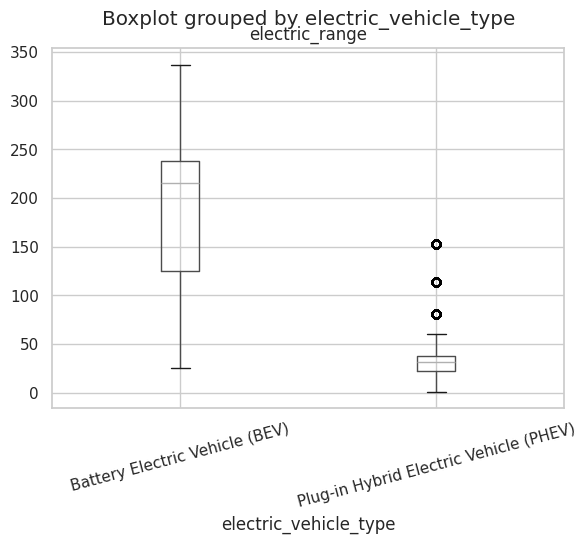

In [13]:
# Only describe columns that actually exist in the DataFrame
available_cols = [col for col in ["electric_range", "base_msrp"] if col in df.columns]
print(df[available_cols].describe())

#Check result
import matplotlib.pyplot as plt
df.boxplot(column="electric_range", by="electric_vehicle_type")
plt.xticks(rotation=15)
plt.show()

# 3. EXPLORATORY DATA ANALYSIS & VISUALIZATIONS

### Step 1: Overview of the cleaned data
Checks the structure of the data (shape, column types, unique values), prints summary statistics for numeric and text columns, and reports the percentage of missing values and duplicate vehicle IDs.

In [14]:
#Set up and load the cleaned data
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# The cleaned dataframe is already loaded in memory as 'df' from previous cells
# We will use 'df' directly instead of reading a file that does not exist yet

#Understand the structure
print(df.shape)
df.info()
print(df.head())
print(df.nunique().sort_values())

#Summary statistics
print(df.describe().T)                                   # numeric columns
print(df.describe(include="string").T)                   # categorical/string columns
print(df[["electric_range"]].agg(["count", "mean", "median", "std", "min", "max"]))

#Check data quality ONE time
missing = df.isna().sum()
print((missing / len(df) * 100).round(2)[missing > 0].sort_values(ascending=False))
print("duplicate vehicle IDs:", df["dol_vehicle_id"].duplicated().sum())

(299694, 17)
<class 'pandas.core.frame.DataFrame'>
Index: 299694 entries, 0 to 299704
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   vin_prefix              299694 non-null  string 
 1   county                  299694 non-null  string 
 2   city                    299694 non-null  string 
 3   state                   299694 non-null  string 
 4   postal_code             299694 non-null  string 
 5   model_year              299694 non-null  Int64  
 6   make                    299694 non-null  string 
 7   model                   299694 non-null  string 
 8   electric_vehicle_type   299694 non-null  string 
 9   cafv_eligibility        299694 non-null  string 
 10  electric_range          105780 non-null  float64
 11  legislative_district    298915 non-null  float64
 12  dol_vehicle_id          299694 non-null  int64  
 13  vehicle_location        299685 non-null  string 
 14  electric_uti

### Step 2: Shared helpers for the charts
Sets up what every chart below reuses:
* Full names for the vehicle types: **Battery Electric Vehicle (BEV)** and **Plug-in Hybrid Electric Vehicle (PHEV)**.
* Consistent capitalization for make and model names (Tesla, Model 3, BMW, ID.4), stored in the new columns `make_display` and `model_display`.
* A reusable horizontal bar function that sorts bars high to low and adds a count label to each bar.
* A label-wrapping function for long category names, and the shared colours (BEV = blue, PHEV = orange).

In [40]:
#Shared helpers for all charts below (names, colours, labels)
import textwrap, re

BLUE, ORANGE = "#1f77b4", "#ff7f0e"
BEV_LABEL  = "Battery Electric Vehicle (BEV)"
PHEV_LABEL = "Plug-in Hybrid Electric Vehicle (PHEV)"
TYPE_COLORS = {BEV_LABEL: BLUE, PHEV_LABEL: ORANGE}

def clean_type(s):
    """Map the raw vehicle-type text to the full, readable names."""
    if pd.isna(s):
        return pd.NA
    u = str(s).upper()
    if "PHEV" in u or "PLUG-IN" in u:
        return PHEV_LABEL
    if "BEV" in u or "BATTERY" in u:
        return BEV_LABEL
    return str(s)

# Words that should stay fully upper-case in make / model names
ACRONYMS = {"EV", "BMW", "GT", "SUV", "MG", "BYD", "GMC", "PHEV", "BEV", "XPENG"}

def title_case_name(s):
    """Consistent capitalisation: 'TESLA' -> 'Tesla', 'MODEL 3' -> 'Model 3', 'BMW' stays 'BMW'."""
    if pd.isna(s):
        return pd.NA
    out = []
    for w in str(s).split():
        if w.upper() in ACRONYMS or any(ch.isdigit() for ch in w):
            out.append(w.upper())
        else:
            out.append("-".join(p.capitalize() for p in w.split("-")))
    return " ".join(out)

df["vehicle_type_label"] = df["electric_vehicle_type"].map(clean_type)
df["make_display"]  = df["make"].map(title_case_name)
df["model_display"] = df["model"].map(title_case_name)

def wrap(label, width=28):
    return "\n".join(textwrap.wrap(str(label), width)) or str(label)

def hbar_counts(s, title, xlabel="Number of EV records", color=BLUE,
                wrap_width=30, figsize=(8, 4.5), show_pct_of=None, footnote=None, ylabel=None):
    """Horizontal bar chart, sorted high -> low, with a count label on every bar."""
    s = s.sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.barh([wrap(i, wrap_width) for i in s.index], s.values, color=color, height=0.65)
    ax.invert_yaxis()
    if show_pct_of:
        labels = [f"{v:,} ({v / show_pct_of:.1%})" for v in s.values]
    else:
        labels = [f"{v:,}" for v in s.values]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=9)
    ax.set_xlim(0, s.max() * 1.22)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
    if footnote:
        fig.text(0.01, 0.005, footnote, fontsize=8, color="#555555", ha="left", va="bottom")
        fig.tight_layout(rect=(0, 0.04, 1, 1))
    else:
        fig.tight_layout()
    plt.show()

# Notes reused as chart footnotes
N_RANGE = int(df["electric_range"].notna().sum())
RANGE_NOTE = (f"Electric range is recorded for {N_RANGE:,} of {len(df):,} records ({N_RANGE/len(df):.0%}); "
              f"range charts use only those records.")
NOTE_GEO  = "Note: bars show the number of EV records in the dataset, not the number of registrations."
NOTE_YEAR = ("Note: counts are vehicle records in this dataset (the observed vehicle population), "
             "not necessarily all registrations made in each year.")

# Written findings are collected here and printed again in the final summary cell
FINDINGS = []
def report(text):
    FINDINGS.append(text)
    print("-", text)

def short_type(label):
    return "BEV" if label == BEV_LABEL else "PHEV" if label == PHEV_LABEL else str(label)

TOTAL_RECORDS = len(df)

### Step 3: Single-variable charts
* **BEV vs PHEV:** full names, x-axis label (vehicle type), y-axis label (number of EV records), and the count and percentage of total on each bar.
* **CAFV eligibility:** horizontal bars with wrapped labels, axis labels, and the count and percentage on each bar.
* **Top 10 makes and top 10 models:** horizontal bars sorted so the highest count is at the top, with count labels, axis labels and consistent capitalization. Models are shown with their make (e.g. "Tesla Model 3").
* **Electric range distribution:** uses only valid (non-missing, positive) range values, has axis labels, a footnote on missing data and a printed interpretation. Roughly two thirds of records have no recorded range (105,780 of 299,694 had one in the original run), so the histogram describes vehicles with a recorded range, not the whole fleet.
* **Model year distribution:** axis labels added.

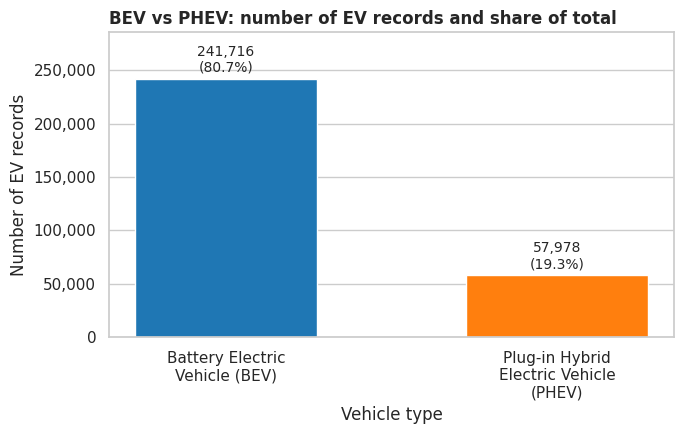

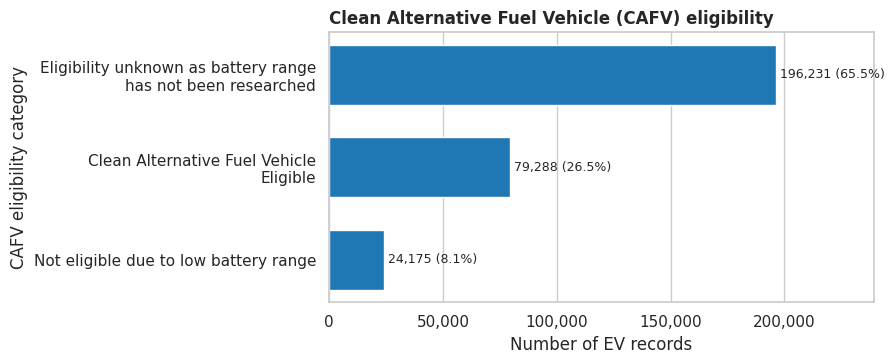

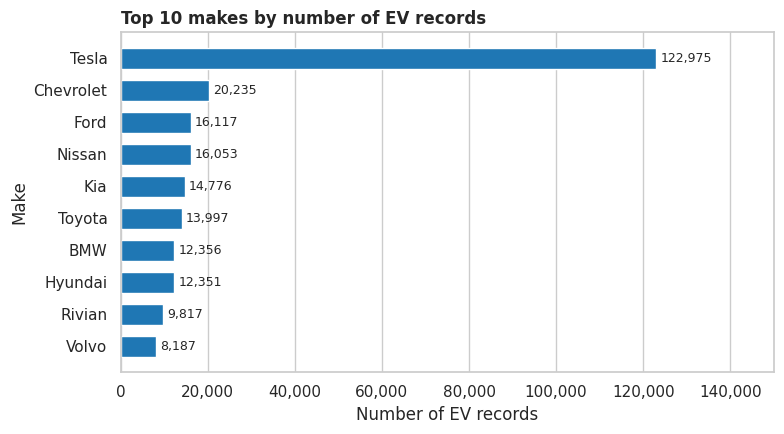

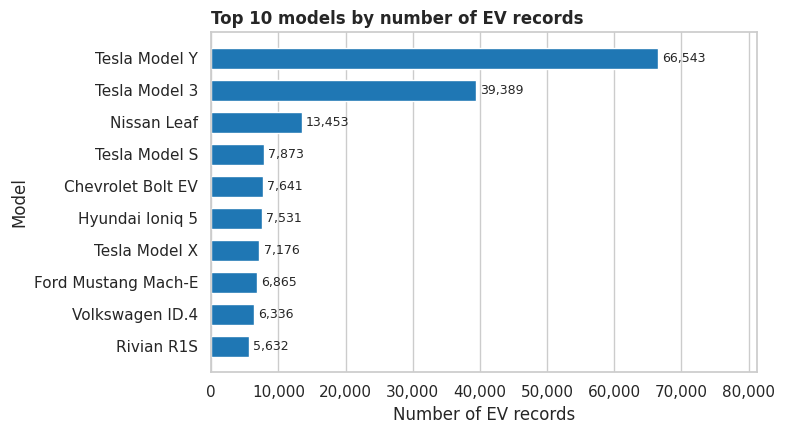

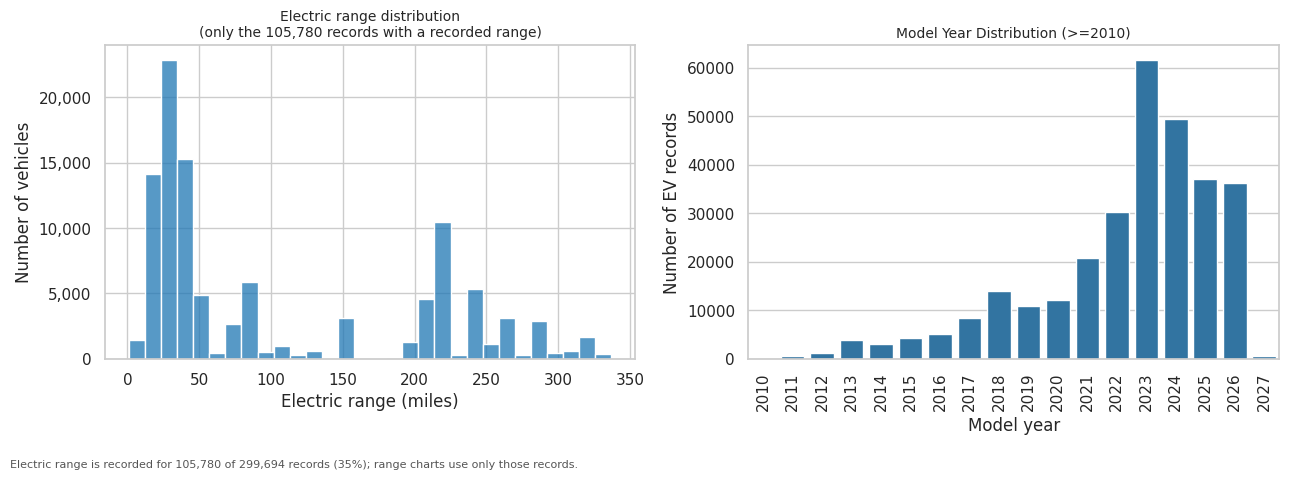

Interpretation of the range distribution
- Electric range is missing for 193,914 of 299,694 records (65%). The histogram uses only the 105,780 valid values, so it describes vehicles with a recorded range, not the whole fleet.
- Among those vehicles the median range is 42 mi, and the middle 50% fall between 30 and 215 mi.
Findings
- Battery electric vehicles are 81% of EV records and plug-in hybrids 19%.
- Tesla is the largest make with 122,975 records (41% of the total).
- The largest CAFV category is 'Eligibility unknown as battery range has not been researched' with 196,231 records (65%).


In [18]:
#Univariate analysis (one variable at a time)

#BEV vs PHEV: full names, count labels and percentages
type_counts = df["vehicle_type_label"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar([wrap(i, 22) for i in type_counts.index], type_counts.values,
              color=[TYPE_COLORS.get(i, "grey") for i in type_counts.index], width=0.55)
ax.bar_label(bars, labels=[f"{v:,}\n({v / type_counts.sum():.1%})" for v in type_counts.values],
             padding=3, fontsize=10)
ax.set_ylim(0, type_counts.max() * 1.18)
ax.set_title("BEV vs PHEV: number of EV records and share of total", loc="left", fontweight="bold")
ax.set_ylabel("Number of EV records")
ax.set_xlabel("Vehicle type")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

#CAFV eligibility: horizontal bars + wrapped labels, count (and %) on each bar
hbar_counts(df["cafv_eligibility"].value_counts(),
            "Clean Alternative Fuel Vehicle (CAFV) eligibility",
            wrap_width=38, figsize=(9, 3.8), ylabel="CAFV eligibility category", show_pct_of=df["cafv_eligibility"].notna().sum())

#Top 10 makes and models (consistent capitalisation, count labels)
hbar_counts(df["make_display"].value_counts().head(10), "Top 10 makes by number of EV records", ylabel="Make")

top_models = df.groupby(["make_display", "model_display"]).size().nlargest(10)
top_models.index = [f"{mk} {md}" for mk, md in top_models.index]
hbar_counts(top_models, "Top 10 models by number of EV records", ylabel="Model")

#Electric range distribution: only valid (non-missing, positive) range values are used
valid_range = df["electric_range"].dropna()
valid_range = valid_range[valid_range > 0]
n_missing = len(df) - len(valid_range)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.histplot(valid_range, bins=30, ax=ax[0], color=BLUE)
ax[0].set_title(f"Electric range distribution\n(only the {len(valid_range):,} records with a recorded range)", fontsize=10)
ax[0].set_xlabel("Electric range (miles)"); ax[0].set_ylabel("Number of vehicles")
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
sns.countplot(x="model_year", data=df[df["model_year"] >= 2010], ax=ax[1], color=BLUE)
ax[1].set_title("Model Year Distribution (>=2010)", fontsize=10)
ax[1].set_xlabel("Model year"); ax[1].set_ylabel("Number of EV records")
ax[1].tick_params(axis="x", rotation=90)
fig.text(0.01, 0.005, RANGE_NOTE, fontsize=8, color="#555555", ha="left", va="bottom")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

print("Interpretation of the range distribution")
q1, med, q3 = valid_range.quantile([0.25, 0.5, 0.75])
report(f"Electric range is missing for {n_missing:,} of {len(df):,} records ({n_missing / len(df):.0%}). "
       f"The histogram uses only the {len(valid_range):,} valid values, so it describes vehicles with a recorded range, not the whole fleet.")
report(f"Among those vehicles the median range is {med:.0f} mi, and the middle 50% fall between {q1:.0f} and {q3:.0f} mi.")

print("Findings")
bev_share = (df["vehicle_type_label"] == BEV_LABEL).mean()
report(f"Battery electric vehicles are {bev_share:.0%} of EV records and plug-in hybrids {1 - bev_share:.0%}.")
mk_counts = df["make_display"].value_counts()
report(f"{mk_counts.index[0]} is the largest make with {mk_counts.iloc[0]:,} records ({mk_counts.iloc[0] / len(df):.0%} of the total).")
cafv_counts = df["cafv_eligibility"].value_counts()
report(f"The largest CAFV category is '{cafv_counts.index[0]}' with {cafv_counts.iloc[0]:,} records "
       f"({cafv_counts.iloc[0] / cafv_counts.sum():.0%}).")

### Step 4: Top models within the top 4 makes
Now uses the consistent make and model capitalization and adds a count label to each bar.

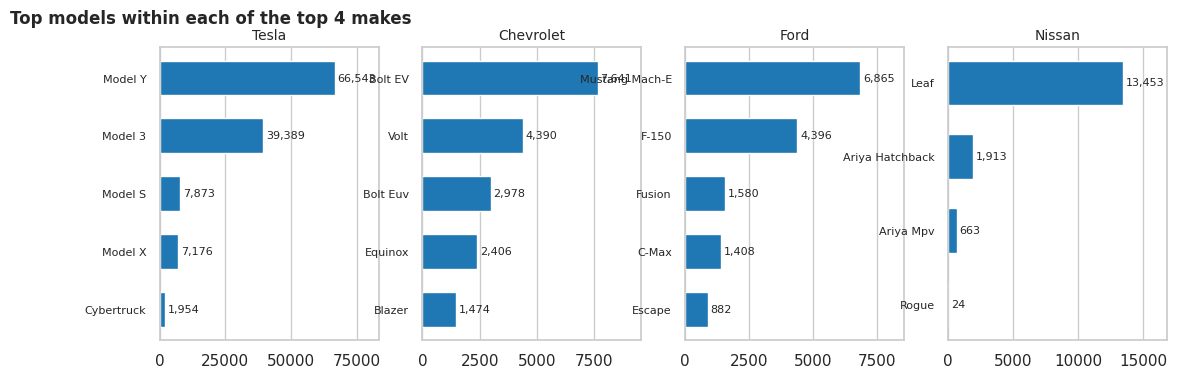

In [23]:
# Top models inside the top 4 makes
top4 = df["make_display"].value_counts().head(4).index
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8))
for ax, make in zip(axes, top4):
    m = df.loc[df["make_display"] == make, "model_display"].value_counts().head(5).sort_values()
    bars = ax.barh(m.index, m.values, height=0.6, color=BLUE)
    ax.bar_label(bars, labels=[f"{v:,}" for v in m.values], padding=2, fontsize=8)
    ax.set_xlim(0, m.max() * 1.25)
    ax.set_title(make, fontsize=10)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Top models within each of the top 4 makes", x=0.01, ha="left", fontsize=12, fontweight="bold")

# Safely attempt to save or display
try:
    save(fig, "10_top_models_by_make")
except NameError:
    plt.show()

### Step 5: Check outliers in electric range
Boxplot of electric range, plus a table of the 10 vehicles with the highest recorded range.

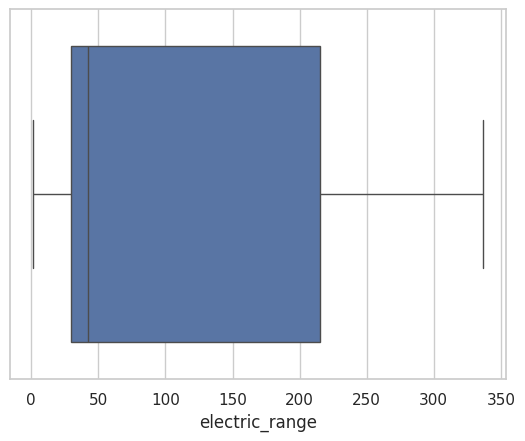

,make,model,model_year,electric_range
1179,TESLA,MODEL S,2020,337.0
2450,TESLA,MODEL S,2020,337.0
5208,TESLA,MODEL S,2020,337.0
9083,TESLA,MODEL S,2020,337.0
11915,TESLA,MODEL S,2020,337.0
14315,TESLA,MODEL S,2020,337.0
18853,TESLA,MODEL S,2020,337.0
20726,TESLA,MODEL S,2020,337.0
22656,TESLA,MODEL S,2020,337.0
38008,TESLA,MODEL S,2020,337.0


In [24]:
#Outliers
sns.boxplot(x=df["electric_range"]); plt.show()
df.nlargest(10, "electric_range")[["make", "model", "model_year", "electric_range"]]

### Step 6: Trends over time
* **EV records by model year:** the stacked BEV/PHEV chart is kept but retitled, with a note that it shows records in the observed vehicle population, not all registrations made in each year.
* **Median electric range by model year:** kept, with axis labels and a grid on both axes so changes in the median are easier to read. The number of vehicles (n) is shown under each year. Years with fewer than 100 vehicles get red hollow markers, and footnotes say that such years may be less reliable and how many records have a recorded range.
* Both charts are followed by printed findings.

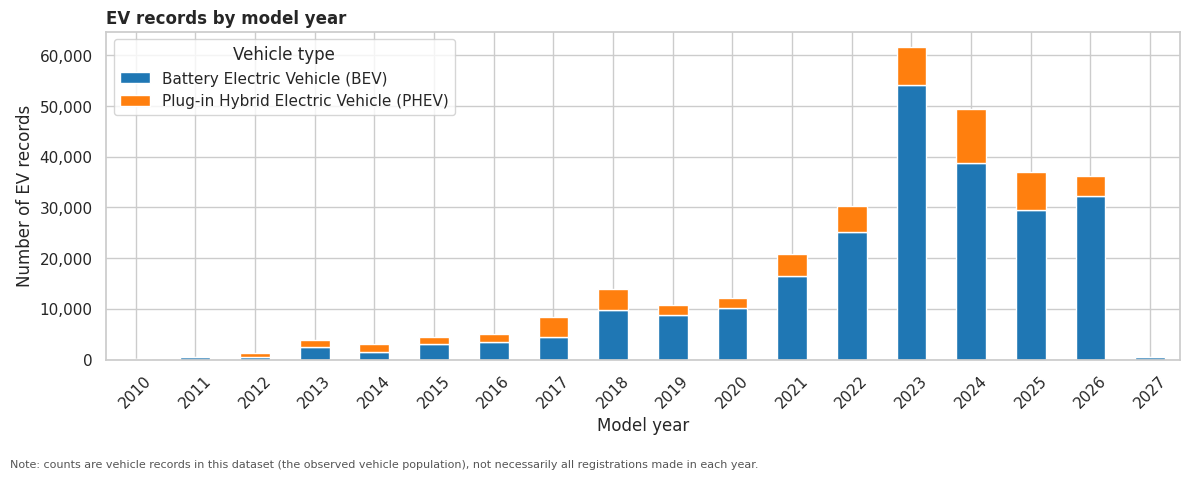

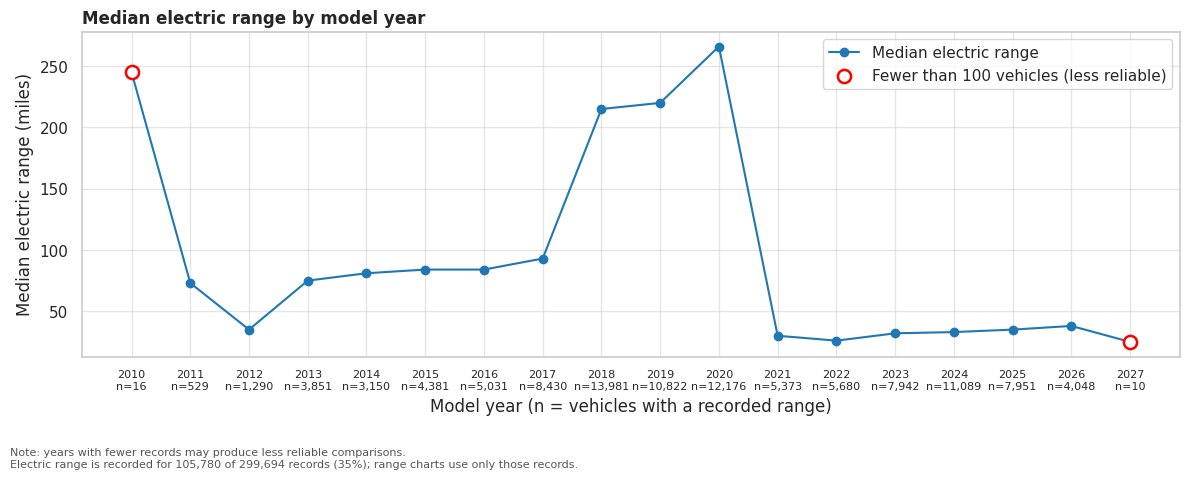

Findings
- EV records by model year peak at model year 2023 (61,594 records).
- Overall median electric range goes from 73 mi (model year 2011) to 38 mi (2026), using only years with at least 100 vehicles that have a recorded range.


In [25]:
#TRENDS OVER TIME
NOTE_YEAR = ("Note: counts are vehicle records in this dataset (the observed vehicle population), "
             "not necessarily all registrations made in each year.")

#EV records by model year, stacked by vehicle type
by_year = (df.groupby(["model_year", "vehicle_type_label"]).size().unstack(fill_value=0)
             .reindex(columns=[BEV_LABEL, PHEV_LABEL], fill_value=0))
fig, ax = plt.subplots(figsize=(12, 4.8))
by_year.loc[2010:].plot(kind="bar", stacked=True, ax=ax,
                        color=[TYPE_COLORS[c] for c in by_year.columns])
ax.set_title("EV records by model year", loc="left", fontweight="bold")
ax.set_xlabel("Model year"); ax.set_ylabel("Number of EV records")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Vehicle type")
fig.text(0.01, 0.005, NOTE_YEAR, fontsize=8, color="#555555", ha="left", va="bottom")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

#Median electric range by model year, with number of vehicles per year
LOW_N = 100   # years with fewer vehicles than this are flagged as less reliable
yr = (df[df["model_year"] >= 2010].groupby("model_year")["electric_range"]
        .agg(median="median", n="count"))      # n = vehicles with a recorded range
yr.index = yr.index.astype(int)

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(yr.index, yr["median"], marker="o", color=BLUE, label="Median electric range")
low = yr[yr["n"] < LOW_N]
ax.scatter(low.index, low["median"], s=90, facecolors="white", edgecolors="red",
           linewidths=1.8, zorder=3, label=f"Fewer than {LOW_N} vehicles (less reliable)")
ax.set_xticks(yr.index)
ax.set_xticklabels([f"{y}\nn={n:,}" for y, n in zip(yr.index, yr["n"])], fontsize=8)
ax.set_title("Median electric range by model year", loc="left", fontweight="bold")
ax.set_xlabel("Model year (n = vehicles with a recorded range)"); ax.set_ylabel("Median electric range (miles)")
ax.grid(True, axis="both", alpha=0.5)   # grid on both axes to make changes easier to read
ax.legend()
fig.text(0.01, 0.005, "Note: years with fewer records may produce less reliable comparisons.\n" + RANGE_NOTE,
         fontsize=8, color="#555555", ha="left", va="bottom")
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

print("Findings")
tot_by_year = by_year.sum(axis=1).loc[2010:]
peak = int(tot_by_year.idxmax())
report(f"EV records by model year peak at model year {peak} ({int(tot_by_year.loc[peak]):,} records).")
ok = yr[yr["n"] >= LOW_N]
if len(ok) >= 2:
    report(f"Overall median electric range goes from {ok['median'].iloc[0]:.0f} mi (model year {ok.index[0]}) to "
           f"{ok['median'].iloc[-1]:.0f} mi ({ok.index[-1]}), using only years with at least {LOW_N} vehicles that have a recorded range.")

### Step 7: Cumulative EV records by model year
Running total of EV records from model year 2010 onward, to show how fast the fleet grew.

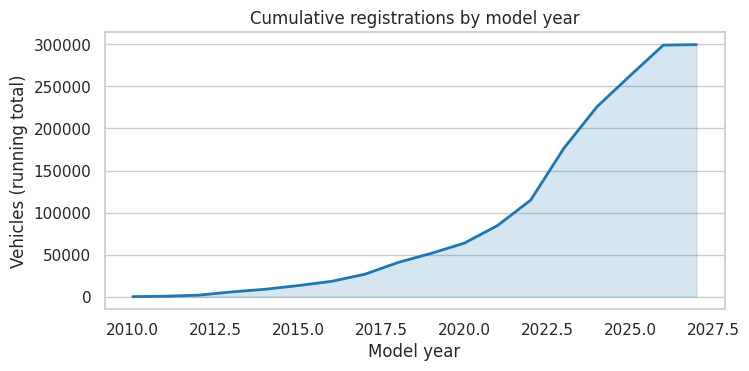

In [27]:
#Cumulative registrations by model year
BLUE = "#1f77b4"
cum = df[df["model_year"] >= 2010].groupby("model_year").size().cumsum()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.fill_between(cum.index.astype(int), cum.values, color=BLUE, alpha=0.18)
ax.plot(cum.index.astype(int), cum.values, color=BLUE, linewidth=2)
ax.set_title("Cumulative registrations by model year")
ax.set_xlabel("Model year"); ax.set_ylabel("Vehicles (running total)")
ax.grid(axis="x", visible=False)

# Safely attempt to save or display
try:
    save(fig, "03_cumulative_growth")
except NameError:
    plt.show()

### Step 8: Electric range vs model year
Scatter plot of electric range for each model year (2010 onward) with the yearly median drawn as a line, to show whether range improves over time.

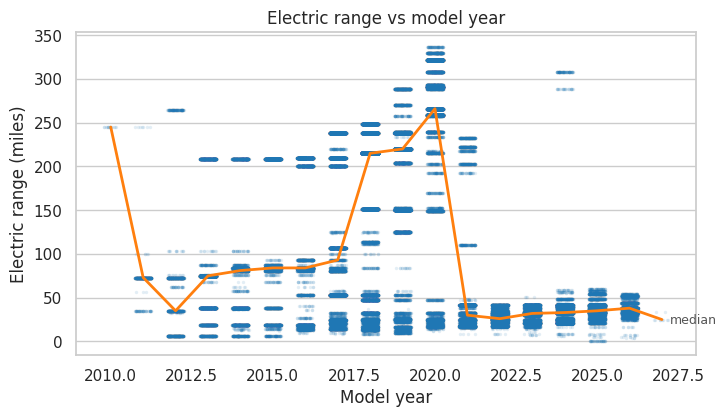

In [28]:
# model year vs electric range (relationship)
INK = "#ff7f0e"  # Distinct color for the median trendline
INK2 = "#555555" # Secondary color for annotations

rel = df[["model_year", "electric_range"]].dropna()
rel = rel[rel["model_year"] >= 2010]
if len(rel) > 10:
    fig, ax = plt.subplots(figsize=(8, 4.2))
    jitter = np.random.default_rng(0).uniform(-0.25, 0.25, len(rel))
    ax.scatter(rel["model_year"] + jitter, rel["electric_range"], s=6, color=BLUE, alpha=0.12, linewidths=0)
    med = rel.groupby("model_year")["electric_range"].median()
    ax.plot(med.index, med.values, color=INK, linewidth=2)
    ax.annotate("median", (med.index[-1], med.values[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK2)
    ax.set_title("Electric range vs model year")
    ax.set_xlabel("Model year"); ax.set_ylabel("Electric range (miles)")
    ax.grid(axis="x", visible=False)

    # Safely attempt to save or display
    try:
        save(fig, "07_range_vs_year")
    except NameError:
        plt.show()

### Step 9: Top 5 makes over time
Line chart of the number of records per model year (2012 onward) for the 5 makes with the most records.

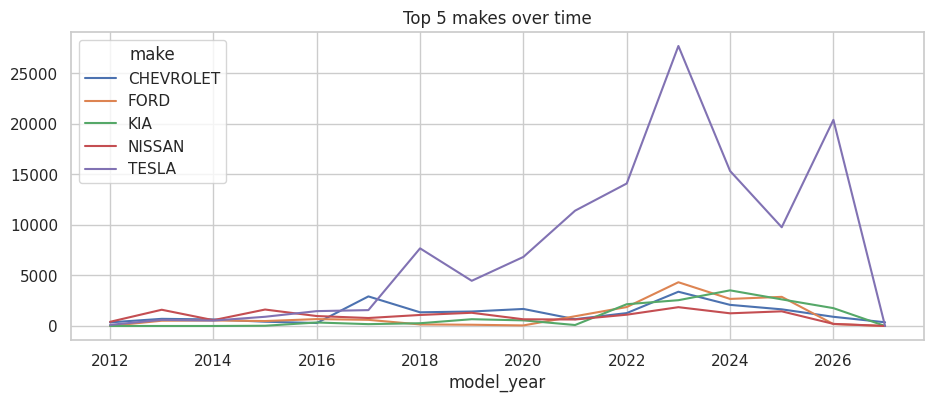

In [ ]:
#Multivariate view
top5 = df["make"].value_counts().head(5).index
trend = (df[df["make"].isin(top5) & (df["model_year"] >= 2012)]
         .groupby(["model_year", "make"]).size().unstack(fill_value=0))
trend.plot(figsize=(11, 4), title="Top 5 makes over time"); plt.show()

### Step 10: Geographic analysis
* **Top 10 counties and top 15 cities:** horizontal bars sorted highest to lowest (highest at the top) with count labels, axis labels, and a note that the bars are record counts in the dataset.
* **Latitude/longitude scatter:** axis labels added and an equal aspect ratio set so the geographic pattern is not stretched.
* The top-3-county share is unchanged.

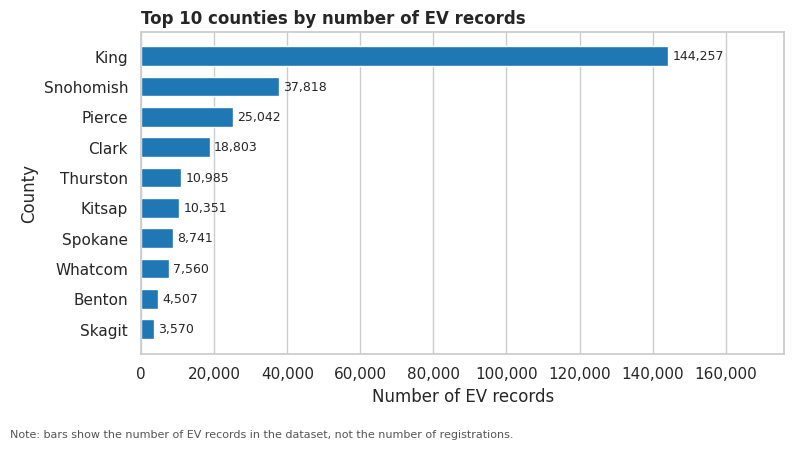

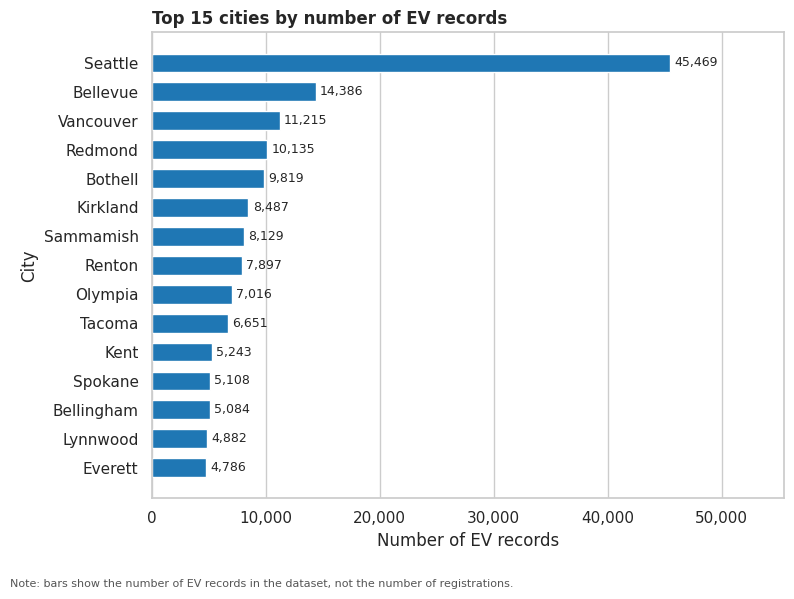

69.1 % of all EV records


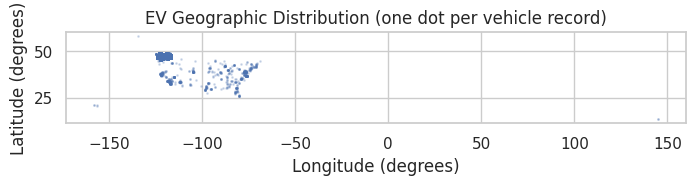

In [29]:
#GEOGRAPHIC ANALYSIS
NOTE_GEO = "Note: bars show the number of EV records in the dataset, not the number of registrations."

top_counties = df["county"].value_counts().head(10)
hbar_counts(top_counties, "Top 10 counties by number of EV records", ylabel="County", footnote=NOTE_GEO)

hbar_counts(df["city"].value_counts().head(15), "Top 15 cities by number of EV records",
            figsize=(8, 6), ylabel="City", footnote=NOTE_GEO)

# Share of the total held by the top 3 counties
print((top_counties.head(3).sum() / len(df) * 100).round(1), "% of all EV records")

# Extract latitude and longitude from the vehicle_location column
if "vehicle_location" in df.columns:
    # Extract float values from POINT (X Y) format
    coords = df["vehicle_location"].str.extract(r"POINT \((?P<longitude>-?\d+\.\d+)\s+(?P<latitude>-?\d+\.\d+)\)")
    df["longitude"] = pd.to_numeric(coords["longitude"], errors="coerce")
    df["latitude"] = pd.to_numeric(coords["latitude"], errors="coerce")

# Optional map (rows with coordinates only), equal aspect ratio so the shape is not stretched
ax = df.dropna(subset=["latitude", "longitude"]).plot.scatter(
    x="longitude", y="latitude", s=1, alpha=0.2, figsize=(8, 6))
ax.set_xlabel("Longitude (degrees)"); ax.set_ylabel("Latitude (degrees)")
ax.set_aspect("equal", adjustable="box")
ax.set_title("EV Geographic Distribution (one dot per vehicle record)")
plt.show()

### Step 11: Concentration by county
Shows how much of the dataset sits in the largest counties: the cumulative share of all EV records as counties are added from largest to smallest, with the top 1, 3 and 5 marked.

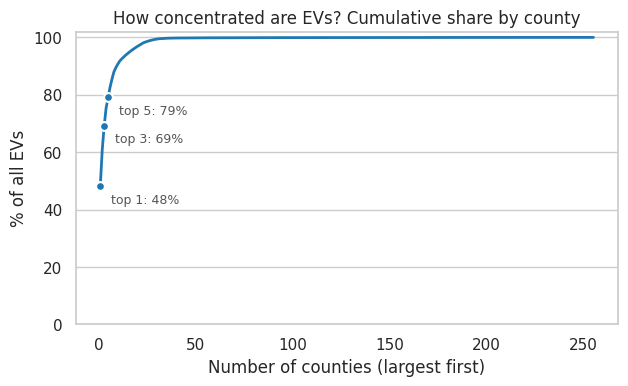

In [30]:
# concentration curve (how concentrated by county)
c = df["county"].value_counts()
share = c.cumsum() / c.sum() * 100
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(range(1, len(share) + 1), share.values, color=BLUE, linewidth=2)
for k in (1, 3, 5):
    if len(share) >= k:
        ax.scatter(k, share.iloc[k - 1], color=BLUE, s=40, zorder=3, edgecolor="white", linewidth=1.5)
        ax.annotate(f"top {k}: {share.iloc[k - 1]:.0f}%", (k, share.iloc[k - 1]), xytext=(8, -12),
                    textcoords="offset points", fontsize=9, color="#555555")
ax.set_title("How concentrated are EVs? Cumulative share by county")
ax.set_xlabel("Number of counties (largest first)"); ax.set_ylabel("% of all EVs"); ax.set_ylim(0, 102)
ax.grid(axis="x", visible=False)

# Safely attempt to save or display
try:
    save(fig, "04_county_concentration")
except NameError:
    plt.show()

### Step 12: Top utilities and legislative districts
* The utility column in this dataset is `electric_utility`, so the old code looked for a column that did not exist and skipped the utilities chart. It now finds the right column.
* Utility names are cleaned (title case, `||` shown as " / ") and districts are shown as "District N" instead of "32.0".
* Both charts use the same style as the other charts: count labels, sorted high to low, and a note that bars are EV records, not registrations.

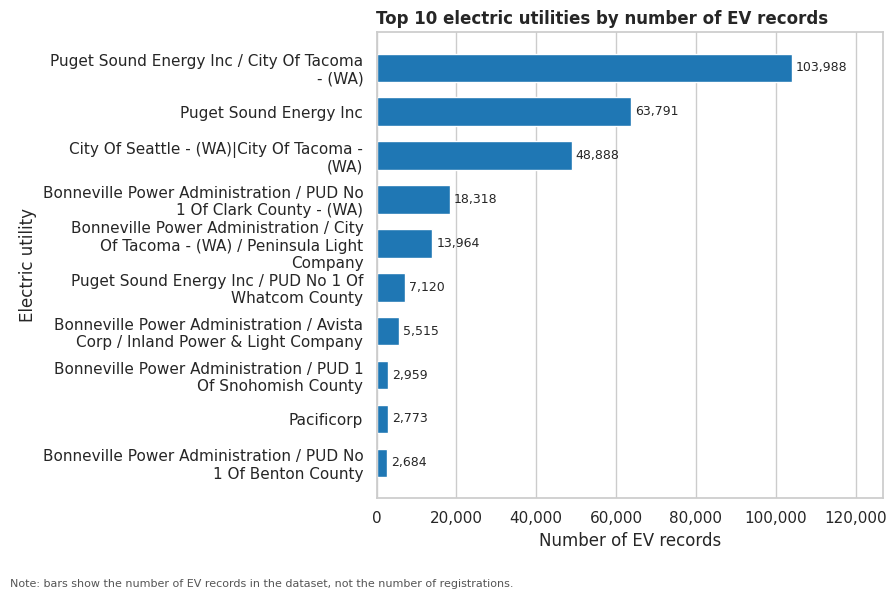

- Puget Sound Energy Inc / City Of Tacoma - (WA) serves the most EV records (103,988; 35% of the total).


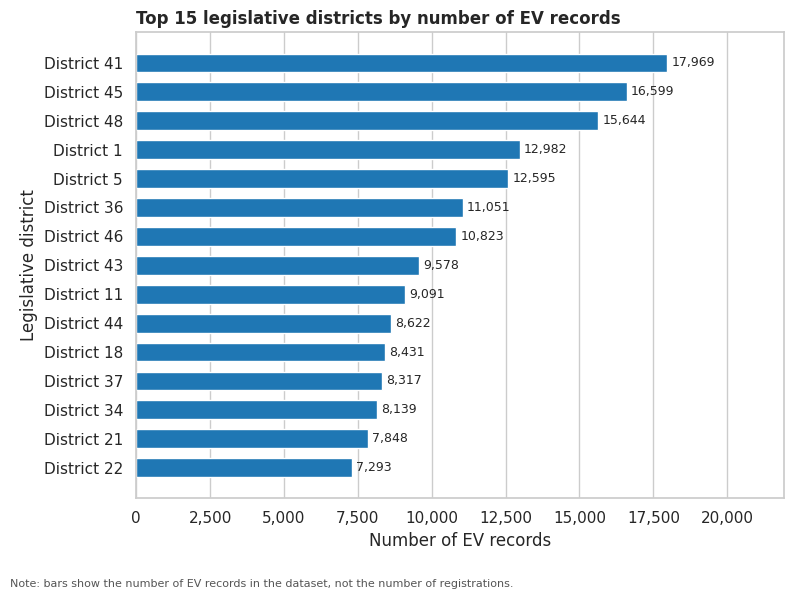

- District 41 has the most EV records (17,969).


In [31]:
# Top electric utilities and legislative districts (record counts, same style as the other charts)
UTILITY_ACRONYMS = {"WA", "PUD", "LLC", "BPA"}

def clean_utility(s):
    """'PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)' -> 'Puget Sound Energy Inc / City Of Tacoma - (WA)'"""
    s = str(s).replace("||", " / ")
    return re.sub(r"[A-Za-z]+",
                  lambda m: m.group(0).upper() if m.group(0).upper() in UTILITY_ACRONYMS else m.group(0).capitalize(), s)

# the column is called electric_utility in this dataset (electric_utility_primary in older exports)
util_col = next((c for c in ["electric_utility", "electric_utility_primary"] if c in df.columns), None)
if util_col:
    util = df[util_col].dropna().map(clean_utility).value_counts().head(10)
    hbar_counts(util, "Top 10 electric utilities by number of EV records",
                wrap_width=40, figsize=(9, 6), ylabel="Electric utility", footnote=NOTE_GEO)
    report(f"{util.index[0]} serves the most EV records ({util.iloc[0]:,}; {util.iloc[0] / len(df):.0%} of the total).")

if "legislative_district" in df.columns:
    dist = pd.to_numeric(df["legislative_district"], errors="coerce").dropna().astype(int).value_counts().head(15)
    dist.index = [f"District {i}" for i in dist.index]
    hbar_counts(dist, "Top 15 legislative districts by number of EV records",
                figsize=(8, 6), ylabel="Legislative district", footnote=NOTE_GEO)
    report(f"{dist.index[0]} has the most EV records ({dist.iloc[0]:,}).")

### Step 13: Bivariate analysis (two variables together)
Compares electric range between BEV and PHEV and across the top 8 makes (boxplots), then tabulates the BEV/PHEV mix per make and the CAFV eligibility mix for the top 8 counties.

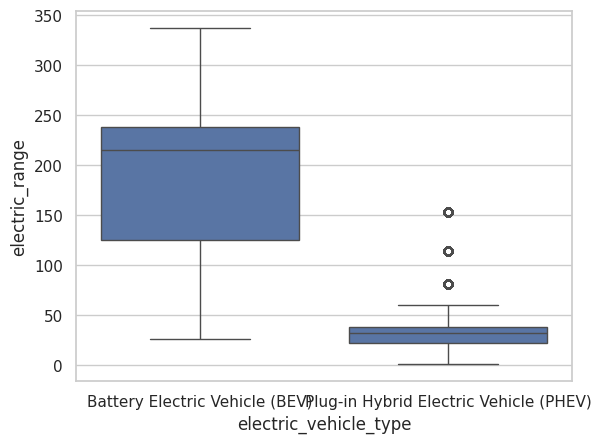

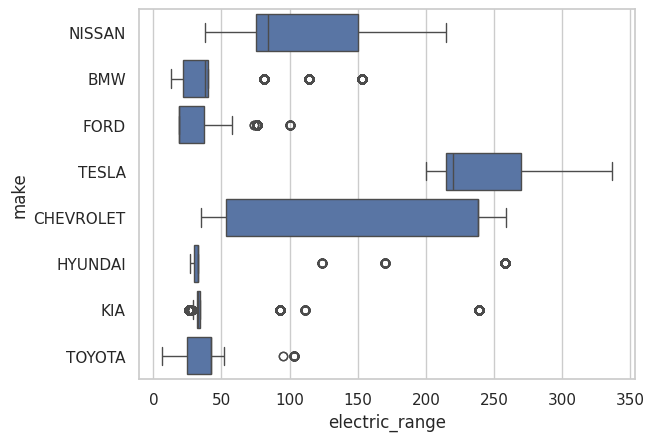

electric_vehicle_type,Battery Electric Vehicle (BEV),Plug-in Hybrid Electric Vehicle (PHEV)
make,,
BMW,0.44,0.56
CHEVROLET,0.78,0.22
FORD,0.76,0.24
HYUNDAI,0.89,0.11
KIA,0.70,0.30
NISSAN,1.00,0.00
TESLA,1.00,0.00
TOYOTA,0.23,0.77


cafv_eligibility,Clean Alternative Fuel Vehicle Eligible,Eligibility unknown as battery range has not been researched,Not eligible due to low battery range
county,,,
Clark,0.28,0.63,0.09
King,0.25,0.68,0.07
Kitsap,0.29,0.61,0.10
Pierce,0.27,0.64,0.09
Snohomish,0.23,0.70,0.07
Spokane,0.27,0.61,0.12
Thurston,0.29,0.61,0.10
Whatcom,0.33,0.58,0.10


In [32]:
#Bivariate analysis (two variables together)
from IPython.display import display
sns.boxplot(x="electric_vehicle_type", y="electric_range", data=df); plt.show()

top_makes = df["make"].value_counts().head(8).index
sns.boxplot(y="make", x="electric_range", data=df[df["make"].isin(top_makes)]); plt.show()

display(pd.crosstab(df["make"].where(df["make"].isin(top_makes)), df["electric_vehicle_type"],
            normalize="index").round(2))          # BEV/PHEV mix per make

display(pd.crosstab(df["county"].where(df["county"].isin(df["county"].value_counts().head(8).index)),
            df["cafv_eligibility"], normalize="index").round(2))

### Step 14: BEV vs PHEV percentage by manufacturer
A 100% stacked horizontal bar for the top 10 manufacturers by record count. Each segment shows the BEV or PHEV percentage, and each manufacturer's total record count is shown next to its name. Printed findings name the most BEV-heavy and PHEV-heavy makes.

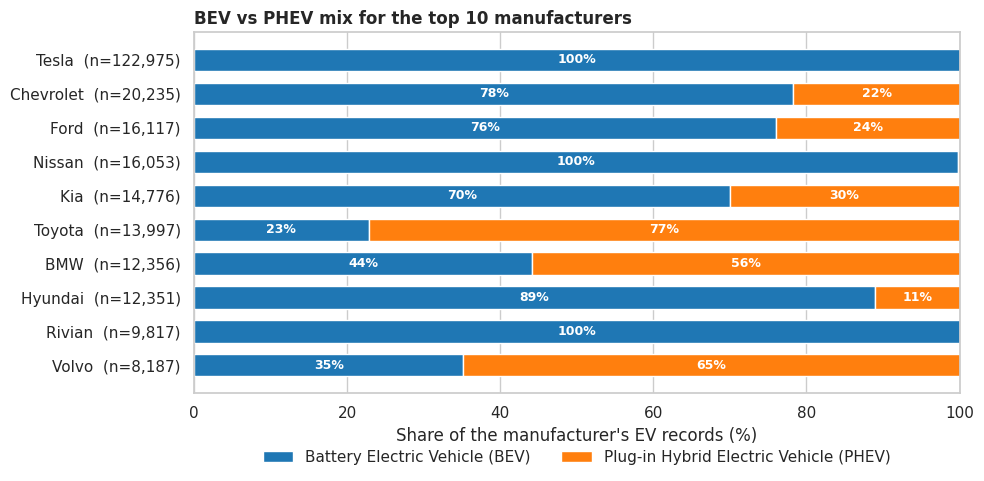

Findings
- Most BEV-heavy leading make: Tesla (100% BEV).
- Most PHEV-heavy leading make: Toyota (77% PHEV).
- Leading makes that are mostly PHEV: Toyota (77%), Volvo (65%), BMW (56%).


In [34]:
#BEV vs PHEV percentage by manufacturer (100% stacked bar, leading manufacturers)
TOP_N = 10
lead = df["make_display"].value_counts().head(TOP_N)
mix = (pd.crosstab(df.loc[df["make_display"].isin(lead.index), "make_display"],
                   df["vehicle_type_label"], normalize="index") * 100)
mix = mix.reindex(index=lead.index, columns=[BEV_LABEL, PHEV_LABEL], fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
left = np.zeros(len(mix))
for col in mix.columns:
    bars = ax.barh(range(len(mix)), mix[col].values, left=left, color=TYPE_COLORS[col],
                   height=0.65, label=col)
    ax.bar_label(bars, labels=[f"{v:.0f}%" if v >= 4 else "" for v in mix[col].values],
                 label_type="center", color="white", fontsize=9, fontweight="bold")
    left += mix[col].values
ax.set_yticks(range(len(mix)))
ax.set_yticklabels([f"{m}  (n={lead[m]:,})" for m in mix.index])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of the manufacturer's EV records (%)")
ax.set_title(f"BEV vs PHEV mix for the top {TOP_N} manufacturers", loc="left", fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print("Findings")
report(f"Most BEV-heavy leading make: {mix[BEV_LABEL].idxmax()} ({mix[BEV_LABEL].max():.0f}% BEV).")
report(f"Most PHEV-heavy leading make: {mix[PHEV_LABEL].idxmax()} ({mix[PHEV_LABEL].max():.0f}% PHEV).")
phev_major = mix[mix[PHEV_LABEL] > 50].sort_values(PHEV_LABEL, ascending=False)
if len(phev_major):
    report("Leading makes that are mostly PHEV: " + ", ".join(f"{m} ({v:.0f}%)" for m, v in phev_major[PHEV_LABEL].items()) + ".")
else:
    report("None of the leading makes is mostly PHEV.")

### Step 15: Median electric range by manufacturer
Takes the **15 leading manufacturers by total record count**, keeps those with at least **500 records with a recorded range** (`MIN_RECORDS`), and sorts the bars by median range. . Each bar shows the median and n, and a footnote states how many records have a range.

Leading 15 makes by record count: 13 shown, 2 excluded (fewer than 500 records with a recorded range).
Excluded: Rivian (n=0), Subaru (n=380)


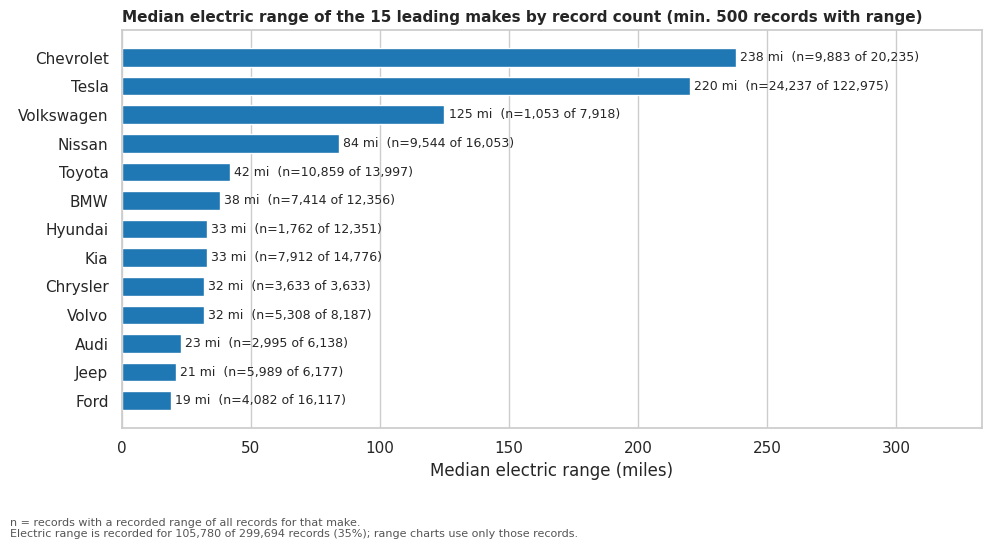

Findings
- Among the leading makes, Chevrolet has the highest median range (238 mi) and Ford the lowest (19 mi).


In [35]:
#Median electric range by manufacturer: leading makes by volume, minimum record-count threshold
MIN_RECORDS = 500    # a make needs at least this many records WITH a recorded range
TOP_RANGE_N = 15     # leading makes by total record count

counts_all = df["make_display"].value_counts()
leading = counts_all.head(TOP_RANGE_N).index
mk = (df[df["make_display"].isin(leading)].groupby("make_display")["electric_range"]
        .agg(median="median", n_range="count"))
mk["n_records"] = counts_all.reindex(mk.index)

excluded = mk[mk["n_range"] < MIN_RECORDS]
plot_mk = mk[mk["n_range"] >= MIN_RECORDS].sort_values("median", ascending=False)   # sorted by median
print(f"Leading {TOP_RANGE_N} makes by record count: {len(plot_mk)} shown, {len(excluded)} excluded "
      f"(fewer than {MIN_RECORDS:,} records with a recorded range).")
if len(excluded):
    print("Excluded:", ", ".join(f"{m} (n={n:,})" for m, n in excluded["n_range"].items()))

if len(plot_mk):
    fig, ax = plt.subplots(figsize=(10, 5.5))
    bars = ax.barh(plot_mk.index, plot_mk["median"], color=BLUE, height=0.65)
    ax.invert_yaxis()
    ax.bar_label(bars, labels=[f"{m:.0f} mi  (n={nr:,} of {nt:,})" for m, nr, nt in
                               zip(plot_mk["median"], plot_mk["n_range"], plot_mk["n_records"])],
                 padding=3, fontsize=9)
    ax.set_xlim(0, plot_mk["median"].max() * 1.4)
    ax.set_xlabel("Median electric range (miles)")
    ax.set_title(f"Median electric range of the {TOP_RANGE_N} leading makes by record count (min. {MIN_RECORDS:,} records with range)",
                 loc="left", fontweight="bold", fontsize=11)
    ax.grid(axis="y", visible=False)
    fig.text(0.01, 0.005, "n = records with a recorded range of all records for that make.\n" + RANGE_NOTE,
             fontsize=8, color="#555555", ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()

    print("Findings")
    hi, lo = plot_mk["median"].idxmax(), plot_mk["median"].idxmin()
    report(f"Among the leading makes, {hi} has the highest median range ({plot_mk.loc[hi, 'median']:.0f} mi) "
           f"and {lo} the lowest ({plot_mk.loc[lo, 'median']:.0f} mi).")

### Step 16: CAFV eligibility by vehicle type
A heatmap with eligibility categories as rows and BEV/PHEV as columns. Each cell shows the record count and the percentage within that vehicle type. Printed findings name the dominant category for each type and the biggest gap between them.

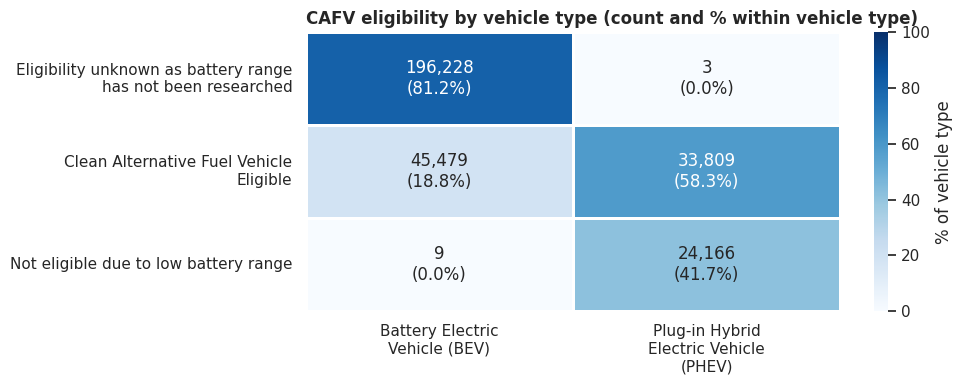

Findings
- For BEV, the largest CAFV category is 'Eligibility unknown as battery range has not been researched' (81% of 241,716 records).
- For PHEV, the largest CAFV category is 'Clean Alternative Fuel Vehicle Eligible' (58% of 57,978 records).
- The biggest gap between types is 'Eligibility unknown as battery range has not been researched': 81% of BEVs vs 0% of PHEVs.


In [36]:
#CAFV eligibility by vehicle type (heatmap: count and % within each vehicle type)
ct = pd.crosstab(df["cafv_eligibility"], df["vehicle_type_label"])
ct = ct.reindex(columns=[c for c in [BEV_LABEL, PHEV_LABEL] if c in ct.columns])
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]
pct = ct / ct.sum(axis=0) * 100

annot = pd.DataFrame(
    [[f"{ct.iloc[i, j]:,}\n({pct.iloc[i, j]:.1f}%)" for j in range(ct.shape[1])] for i in range(ct.shape[0])],
    index=ct.index, columns=ct.columns)

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "% of vehicle type"}, linewidths=1, linecolor="white", ax=ax)
ax.set_yticklabels([wrap(t.get_text(), 38) for t in ax.get_yticklabels()], rotation=0)
ax.set_xticklabels([wrap(t.get_text(), 22) for t in ax.get_xticklabels()], rotation=0)
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("CAFV eligibility by vehicle type (count and % within vehicle type)",
             loc="left", fontweight="bold")
plt.tight_layout()
plt.show()

print("Findings")
for col in ct.columns:
    top = pct[col].idxmax()
    report(f"For {short_type(col)}, the largest CAFV category is '{top}' ({pct.loc[top, col]:.0f}% of {ct[col].sum():,} records).")
if {BEV_LABEL, PHEV_LABEL} <= set(ct.columns):
    gap = (pct[BEV_LABEL] - pct[PHEV_LABEL])
    cat = gap.abs().idxmax()
    report(f"The biggest gap between types is '{cat}': {pct.loc[cat, BEV_LABEL]:.0f}% of BEVs vs {pct.loc[cat, PHEV_LABEL]:.0f}% of PHEVs.")

### Step 17: Median range by model year and vehicle type
Two lines, one for BEVs and one for PHEVs, showing whether their recorded ranges differ across model years. Points based on fewer than 20 vehicles (`MIN_PER_POINT`) are hidden, and a footnote states how many records have a range. Printed findings say whether each line is rising, falling or flat.

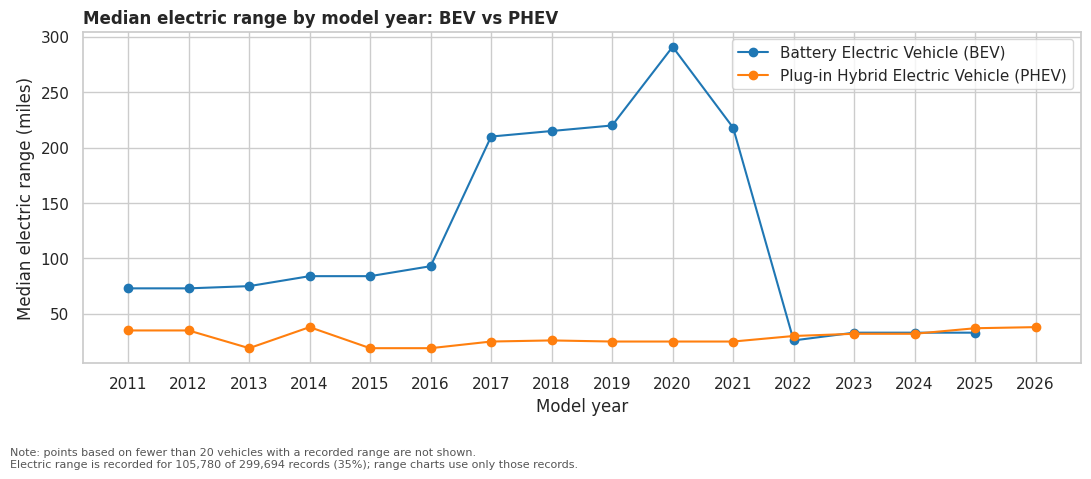

Findings
- BEV median range is roughly flat across model years: 73 mi in 2011 to 33 mi in 2025 (fitted trend -0.5 mi per model year).
- PHEV median range is roughly flat across model years: 35 mi in 2011 to 38 mi in 2026 (fitted trend +0.4 mi per model year).
- In model year 2025, BEV median range is 33 mi vs 37 mi for PHEV (-4 mi).


In [37]:
#Median electric range by model year and vehicle type
MIN_PER_POINT = 20   # hide year/type points built on fewer vehicles than this
mt = (df[df["model_year"] >= 2010].groupby(["model_year", "vehicle_type_label"])["electric_range"]
        .agg(median="median", n="count").reset_index())
mt = mt[mt["n"] >= MIN_PER_POINT]
mt["model_year"] = mt["model_year"].astype(int)

fig, ax = plt.subplots(figsize=(11, 4.8))
for vt in [BEV_LABEL, PHEV_LABEL]:
    s = mt[mt["vehicle_type_label"] == vt]
    ax.plot(s["model_year"], s["median"], marker="o", color=TYPE_COLORS[vt], label=vt)
ax.set_xticks(sorted(mt["model_year"].unique()))
ax.set_xlabel("Model year"); ax.set_ylabel("Median electric range (miles)")
ax.set_title("Median electric range by model year: BEV vs PHEV", loc="left", fontweight="bold")
ax.legend()
fig.text(0.01, 0.005, f"Note: points based on fewer than {MIN_PER_POINT} vehicles with a recorded range are not shown.\n" + RANGE_NOTE,
         fontsize=8, color="#555555", ha="left", va="bottom")
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

print("Findings")
for vt in [BEV_LABEL, PHEV_LABEL]:
    sv = mt[mt["vehicle_type_label"] == vt].sort_values("model_year")
    if len(sv) >= 3:
        slope = np.polyfit(sv["model_year"], sv["median"], 1)[0]
        word = "rising" if slope > 1 else "falling" if slope < -1 else "roughly flat"
        report(f"{short_type(vt)} median range is {word} across model years: {sv['median'].iloc[0]:.0f} mi in "
               f"{sv['model_year'].iloc[0]} to {sv['median'].iloc[-1]:.0f} mi in {sv['model_year'].iloc[-1]} "
               f"(fitted trend {slope:+.1f} mi per model year).")
piv = mt.pivot(index="model_year", columns="vehicle_type_label", values="median").dropna()
if {BEV_LABEL, PHEV_LABEL} <= set(piv.columns) and len(piv):
    y = piv.index.max()
    report(f"In model year {y}, BEV median range is {piv.loc[y, BEV_LABEL]:.0f} mi vs {piv.loc[y, PHEV_LABEL]:.0f} mi for PHEV "
           f"({piv.loc[y, BEV_LABEL] - piv.loc[y, PHEV_LABEL]:+.0f} mi).")

### Step 18: Correlations
Heatmap of the correlation between **model year** and **electric range** only. `legislative_district` was removed because it is an identifier-like geographic code, so its correlation with other variables is not meaningful.

**Limitations of this correlation**
* Pearson's r measures only a straight-line association. It says nothing about cause and effect, and a weak r does not rule out a non-linear pattern.
* Electric range is missing for most records, so r describes only vehicles with a recorded range, which may not represent the whole fleet.
* BEVs and PHEVs have very different ranges and their mix changes by model year, so the overall r can partly reflect that mix. The notebook therefore also prints r for BEVs and PHEVs separately.
* Outliers and imputed range values can pull r up or down.

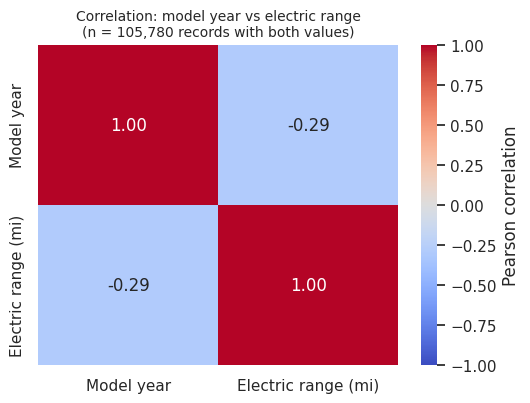

Interpretation
- Across all vehicles, the correlation between model year and electric range is r = -0.29 (based on 105,780 records, because range is missing for the rest).
- Within BEV only: r = 0.36 (n = 47,835).
- Within PHEV only: r = 0.08 (n = 57,945).


In [38]:
#CORRELATIONS: model year and electric range only
# legislative_district is left out: it is an identifier-like geographic code, so its correlation would not be meaningful.
corr_df = pd.DataFrame({
    "Model year": pd.to_numeric(df["model_year"], errors="coerce").astype("float64"),
    "Electric range (mi)": df["electric_range"].astype("float64"),
}).dropna()

fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title(f"Correlation: model year vs electric range\n(n = {len(corr_df):,} records with both values)", fontsize=10)
plt.tight_layout()
plt.show()

print("Interpretation")
r_all = corr_df["Model year"].corr(corr_df["Electric range (mi)"])
report(f"Across all vehicles, the correlation between model year and electric range is r = {r_all:.2f} "
       f"(based on {len(corr_df):,} records, because range is missing for the rest).")
for vt in [BEV_LABEL, PHEV_LABEL]:
    sub = df.loc[df["vehicle_type_label"] == vt, ["model_year", "electric_range"]].dropna()
    if len(sub) > 2:
        r = pd.to_numeric(sub["model_year"]).astype("float64").corr(sub["electric_range"].astype("float64"))
        report(f"Within {short_type(vt)} only: r = {r:.2f} (n = {len(sub):,}).")

# 4. SUMMARY OF FINDINGS

### Step 1: Summary of findings
Prints every finding collected from the charts above in one list. Run all cells first (Runtime > Run all) so the list is complete. All numbers are computed from the data, nothing is typed in by hand.

In [41]:
#Summary of findings (collected from the cells above)
print("KEY FINDINGS\n")
for i, text in enumerate(dict.fromkeys(FINDINGS), 1):
    print(f"{i}. {text}")
print("\nData caveat:", RANGE_NOTE)

KEY FINDINGS


Data caveat: Electric range is recorded for 105,780 of 299,694 records (35%); range charts use only those records.
